# Actividad grupal clase 4 — Simulación de Monte Carlo y MCMC

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Integrantes del grupo:** _(listar aquí a los integrantes)_

Contenido:
1. Miniexploración a mano: un VaR con 20 escenarios y dos pasos de Metropolis
2. Riesgo de plazo de una obra (Monte Carlo)
3. Su propio Metropolis
4. El mismo modelo en PyMC
5. Reflexión

In [1]:
# Celda de instalación: correrla apenas se abra el notebook.
# Si Colab pide reiniciar el entorno después de instalar, reiniciar y seguir desde la celda de import.
try:
    import pymc as pm
    assert int(pm.__version__.split(".")[0]) >= 6
except (ImportError, AssertionError):
    !pip install -q "pymc>=6" nutpie

g++ not available, if using conda: `conda install gxx`


In [2]:
import numpy as np, pymc as pm, arviz as az
import matplotlib.pyplot as plt
from scipy import stats

---
## Parte 1: Miniexploración a mano

### Situación A: un VaR con 20 escenarios

Pérdidas simuladas de la cartera de una cooperativa para el próximo trimestre (millones de colones; los negativos son ganancias):

$$0.4,\ 1.8,\ -0.6,\ 2.9,\ 0.9,\ 3.6,\ 1.2,\ -0.3,\ 2.2,\ 6.4,\ 0.7,\ 1.5,\ 4.3,\ -1.1,\ 2.6,\ 0.1,\ 1.9,\ 9.2,\ 3.1,\ 1.0$$

**1. VaR 95 %.** Ordenados de menor a mayor:

$$-1.1,\ -0.6,\ -0.3,\ 0.1,\ 0.4,\ 0.7,\ 0.9,\ 1.0,\ 1.2,\ 1.5,\ 1.8,\ 1.9,\ 2.2,\ 2.6,\ 2.9,\ 3.1,\ 3.6,\ 4.3,\ \mathbf{6.4},\ 9.2$$

El 5 % más malo de 20 escenarios es un solo escenario: el peor (9.2). El VaR 95 % es el valor que deja al 95 % de los escenarios por debajo: el escenario 19 en el orden, es decir **6.4 millones**. (Con interpolación lineal, `np.percentile(..., 95)` da 6.54; el criterio por escenario ordenado da 6.4.)

**2. Pérdida promedio.** $\frac{1}{20}\sum x_i = \frac{41.8}{20}=$ **2.09 millones**.

| Número | Qué le dice a la gerencia |
|---|---|
| Pérdida promedio = 2.09 M | Lo que se espera perder en un trimestre típico: es el costo "normal" del negocio y lo que se debe cubrir con provisiones. |
| VaR 95 % = 6.4 M | Con 95 % de confianza la pérdida del trimestre **no pasará de 6.4 M**; una vez cada 20 trimestres se espera superarla. Define cuánto capital hay que tener para aguantar un mal trimestre. |

El VaR es ~3 veces la pérdida promedio: la cola pesa mucho, y el VaR no dice **cuánto** se pierde cuando se supera (aquí el peor caso es 9.2 M).

In [3]:
# Verificación en código de la situación A
esc = np.array([0.4, 1.8, -0.6, 2.9, 0.9, 3.6, 1.2, -0.3, 2.2, 6.4,
                0.7, 1.5, 4.3, -1.1, 2.6, 0.1, 1.9, 9.2, 3.1, 1.0])
orden = np.sort(esc)
print("ordenados:", orden)
print("VaR 95 % (escenario 19):", orden[18])
print("pérdida promedio:", esc.mean().round(2))
print("np.percentile 95 (interpolado):", np.percentile(esc, 95).round(2))

ordenados: [-1.1 -0.6 -0.3  0.1  0.4  0.7  0.9  1.   1.2  1.5  1.8  1.9  2.2  2.6
  2.9  3.1  3.6  4.3  6.4  9.2]
VaR 95 % (escenario 19): 6.4
pérdida promedio: 2.09
np.percentile 95 (interpolado): 6.54


### Situación B: dos pasos de Metropolis

De los primeros 40 créditos, 7 cayeron en mora. Con un prior plano, el posterior de la tasa de morosidad $\theta$ es proporcional a

$$g(\theta)=\theta^{7}(1-\theta)^{33}.$$

**3. Verosimilitud y prior.** $\theta^{7}(1-\theta)^{33}$ es la **verosimilitud** (binomial con 7 éxitos y 33 fracasos, sin el coeficiente binomial $\binom{40}{7}$, que es constante en $\theta$). El **prior plano** (uniforme en $(0,1)$) vale 1 en todas partes, por eso "desapareció" al multiplicar: posterior $\propto$ verosimilitud $\times$ prior $=$ verosimilitud.

**4. Dos pasos**, empezando en $\theta_0=0.20$. Se acepta cuando $u<\dfrac{g(\theta')}{g(\theta)}$ (si la razón es mayor que 1 siempre se acepta):

- **Paso 1:** se propone $\theta'=0.15$ y sale $u=0.6$.
$$\frac{g(0.15)}{g(0.20)}=\left(\frac{0.15}{0.20}\right)^{7}\left(\frac{0.85}{0.80}\right)^{33}\approx 0.987>0.6\ \Rightarrow\ \textbf{se acepta},\quad \theta_1=0.15.$$

- **Paso 2:** desde $\theta_1=0.15$ se propone $\theta'=0.30$ y sale $u=0.35$.
$$\frac{g(0.30)}{g(0.15)}=\left(\frac{0.30}{0.15}\right)^{7}\left(\frac{0.70}{0.85}\right)^{33}\approx 0.211<0.35\ \Rightarrow\ \textbf{se rechaza},\quad \theta_2=0.15.$$

Al rechazar, la cadena **se queda** en el valor actual (y ese valor se vuelve a contar en la muestra).

In [4]:
# Verificación en código de la situación B
g = lambda th: th**7 * (1 - th)**33
print("razón paso 1:", round(g(0.15) / g(0.20), 3), "-> u = 0.60:", "acepta" if 0.60 < g(0.15)/g(0.20) else "rechaza")
print("razón paso 2:", round(g(0.30) / g(0.15), 3), "-> u = 0.35:", "acepta" if 0.35 < g(0.30)/g(0.15) else "rechaza")

razón paso 1: 0.987 -> u = 0.60: acepta
razón paso 2: 0.211 -> u = 0.35: rechaza


---
## Parte 2: Riesgo de plazo de una obra

Tres etapas con distribución triangular (mínimo, más probable, máximo), en días: diseño (15, 20, 30), permisos (20, 30, 60) y construcción (40, 50, 70). El contrato fija **120 días**.

**1. Antes de correr el código.** Si cada etapa dura su valor más probable, la obra dura $20+30+50=\mathbf{100}$ días, con 20 días de holgura. A primera vista el riesgo de pasarse parece **bajo**. Pero las distribuciones de permisos y construcción tienen la cola larga hacia la derecha (el máximo está mucho más lejos del valor más probable que el mínimo), así que el riesgo es mayor de lo que sugiere la intuición.

media: 111.6 días
P(total > 120): 0.225
percentil 90: 126.3
9.730633222914552 72.00198855509989 38.95331451950322


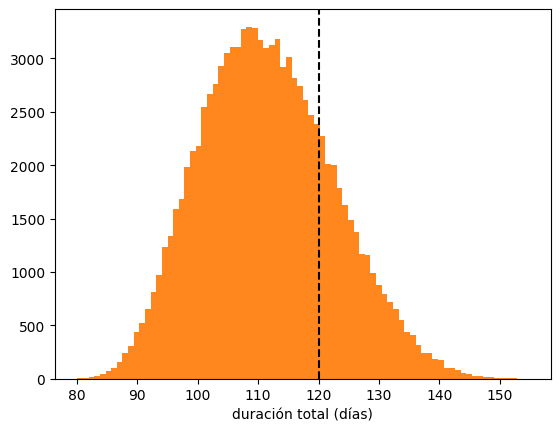

P(total2 > 120): 0.036


In [5]:
rng = np.random.default_rng(2026)
n = 100_000
# triangular(mínimo, más probable, máximo)
diseno = rng.triangular(15, 20, 30, size=n)
permisos = rng.triangular(20, 30, 60, size=n)
obra = rng.triangular(40, 50, 70, size=n)
total = diseno + permisos + obra

print(f"media: {total.mean():.1f} días")                      # 111.6
print(f"P(total > 120): {(total > 120).mean():.3f}")          # 0.225
print(f"percentil 90: {np.percentile(total, 90):.1f}")        # 126.3
print(diseno.var(), permisos.var(), obra.var())

plt.hist(total, bins=80, color="#FF871E")
plt.axvline(120, color="black", ls="--")
plt.xlabel("duración total (días)"); plt.show()

# Escenario: permisos con peor caso de 40 días
permisos2 = rng.triangular(20, 30, 40, size=n)
total2 = diseno + permisos2 + obra
print(f"P(total2 > 120): {(total2 > 120).mean():.3f}")        # 0.036

In [6]:
# Aporte de cada etapa a la incertidumbre (varianza) y comparación con la fórmula exacta
def tri_var(a, c, b):  return (a*a + b*b + c*c - a*b - a*c - b*c) / 18   # c = valor más probable
def tri_mean(a, c, b): return (a + b + c) / 3

vars_ = {"diseño": diseno.var(), "permisos": permisos.var(), "construcción": obra.var()}
exactas = {"diseño": tri_var(15, 20, 30), "permisos": tri_var(20, 30, 60), "construcción": tri_var(40, 50, 70)}
medias = {"diseño": tri_mean(15, 20, 30), "permisos": tri_mean(20, 30, 60), "construcción": tri_mean(40, 50, 70)}
tot_var = sum(vars_.values())
for k in vars_:
    print(f"{k:13s} media exacta = {medias[k]:5.1f}  var simulada = {vars_[k]:5.1f}  var exacta = {exactas[k]:5.1f}  "
          f"aporte = {vars_[k]/tot_var:5.1%}")
print(f"P(total <= 100 días) = {(total <= 100).mean():.3f}   (suma de las modas)")
print(f"suma de las medias exactas = {sum(medias.values()):.1f} días | varianza total = {tot_var:.1f} días²")
print(f"escenario permisos acortado: media {total2.mean():.1f} días, P(>120) baja de {(total > 120).mean():.1%} a {(total2 > 120).mean():.1%}")

diseño        media exacta =  21.7  var simulada =   9.7  var exacta =   9.7  aporte =  8.1%
permisos      media exacta =  36.7  var simulada =  72.0  var exacta =  72.2  aporte = 59.7%
construcción  media exacta =  53.3  var simulada =  39.0  var exacta =  38.9  aporte = 32.3%
P(total <= 100 días) = 0.150   (suma de las modas)
suma de las medias exactas = 111.7 días | varianza total = 120.7 días²
escenario permisos acortado: media 105.0 días, P(>120) baja de 22.5% a 3.6%


**2. Resultados** (semilla 2026): duración media **111.6 días**, probabilidad de pasarse de 120 días **22.5 %** y percentil 90 de **126.3 días**.

**3. ¿Qué etapa aporta más incertidumbre?** **Permisos**: su varianza (~72 días²) es unas 7 veces la de diseño (~9.7) y casi el doble de la de construcción (~39), y explica cerca del **60 %** de la varianza total (~121 días²). Como las etapas son independientes, las varianzas se suman, y la que tiene el rango más ancho (20–60 días) domina.

**4. Si el peor caso de permisos baja de 60 a 40 días**, el riesgo de pasarse de 120 días cae de **22.5 % a 3.6 %** (y la media baja de ~111.6 a ~105 días).

### Pregunta para discutir

- **¿Por qué el plan "más probable" es optimista?** Porque la suma de **modas** (100 días) no es la **media** de la suma. Para una triangular, la media es $(a+b+c)/3$, y cuando la cola derecha es más larga la media queda por encima de la moda: 21.7 + 36.7 + 53.3 = **111.7 días**. Además, en la simulación la obra termina en 100 días o menos solo el **15 %** de las veces: los retrasos posibles (hasta +30 días en permisos, +20 en construcción) son mucho mayores que los adelantos posibles (−10 días en cada una), y hay que sumar tres etapas a la vez. Planificar con valores más probables ignora las colas.
- **¿Dónde invertir el esfuerzo de gestión?** En **permisos**: es la etapa con más varianza y la única donde una gestión (acuerdo con la municipalidad) puede recortar el peor caso; reducir ese máximo de 60 a 40 días baja el riesgo en ~19 puntos porcentuales, mucho más de lo que se lograría ajustando diseño. Construcción sería la segunda prioridad. En general conviene gastar esfuerzo donde está la varianza, no donde está la duración media.

---
## Parte 3: Su propio Metropolis

Línea de crédito de la parte 1 (7 morosos de 40). Se programa Metropolis sobre $\log g(\theta)$ con propuestas normales $\mathcal N(\theta,\,0.1^2)$ y 20 000 pasos desde $\theta=0.5$. Con el **logaritmo** se evitan desbordamientos numéricos, y como solo aparece la **diferencia** de log-densidades, la constante de normalización se cancela.

aceptación: 0.56
media: 0.191
[0.107 0.294]


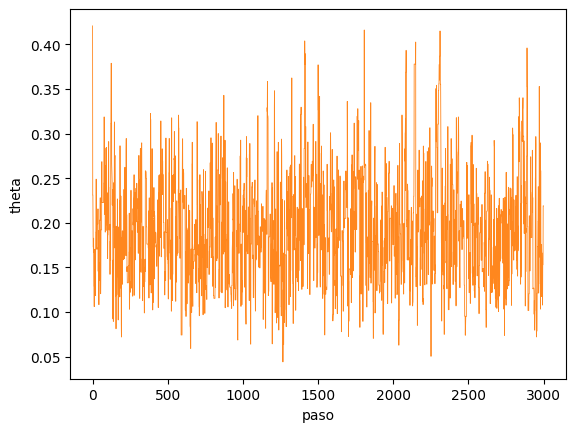

In [7]:
def log_post(theta, k=7, n=40):
    if theta <= 0 or theta >= 1:
        return -np.inf                      # fuera de (0, 1)
    return k * np.log(theta) + (n - k) * np.log(1 - theta)

def metropolis(sd, pasos=20_000, inicio=0.5, semilla=2026):
    rng = np.random.default_rng(semilla)
    theta = inicio
    cadena = np.empty(pasos)
    aceptados = 0
    for t in range(pasos):
        prop = theta + rng.normal(0, sd)                              # propuesta
        if np.log(rng.random()) < log_post(prop) - log_post(theta):    # regla de aceptación
            theta = prop
            aceptados += 1
        cadena[t] = theta
    return cadena, aceptados / pasos

cadena, tasa = metropolis(0.1)
muestras = cadena[2000:]                                              # se descartan los primeros 2000 (calentamiento)
print(f"aceptación: {tasa:.2f}")                                       # 0.56
print(f"media: {muestras.mean():.3f}")                                 # 0.191
print(np.percentile(muestras, [5.5, 94.5]).round(3))                   # [0.107 0.294]

plt.plot(cadena[:3000], lw=0.6, color="#FF871E")
plt.ylabel("theta"); plt.xlabel("paso"); plt.show()

exacta   : media = 0.190, intervalo 89 % = [0.103 0.293]
Metropolis: media = 0.191, intervalo 89 % = [0.107 0.294]

primeros 5 valores de la cadena: [0.421 0.231 0.231 0.2   0.173]
media con todos los pasos: 0.1906   media sin calentamiento: 0.1907


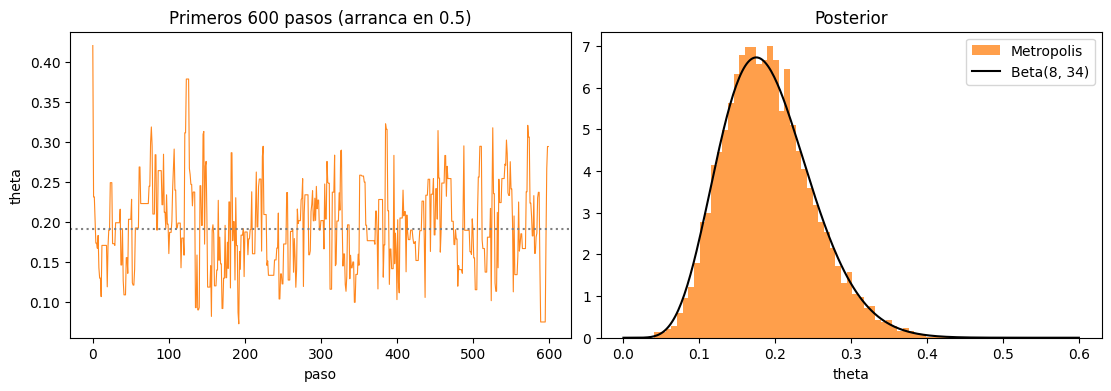

In [8]:
# Comparación con la solución exacta: Beta(8, 34)
exacta = stats.beta(8, 34)
print(f"exacta   : media = {exacta.mean():.3f}, intervalo 89 % = {np.round(exacta.interval(0.89), 3)}")
print(f"Metropolis: media = {muestras.mean():.3f}, intervalo 89 % = {np.percentile(muestras, [5.5, 94.5]).round(3)}")

# ¿Por qué descartar el inicio? Media con y sin calentamiento, y primeros valores de la cadena
print("\nprimeros 5 valores de la cadena:", cadena[:5].round(3))
print(f"media con todos los pasos: {cadena.mean():.4f}   media sin calentamiento: {muestras.mean():.4f}")

# Traza y densidad frente a la Beta(8, 34)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
a1.plot(cadena[:600], lw=0.8, color="#FF871E"); a1.axhline(exacta.mean(), color="gray", ls=":")
a1.set(title="Primeros 600 pasos (arranca en 0.5)", xlabel="paso", ylabel="theta")
a2.hist(muestras, bins=60, density=True, color="#FF871E", alpha=0.8, label="Metropolis")
x = np.linspace(0, 0.6, 300); a2.plot(x, exacta.pdf(x), "k", lw=1.5, label="Beta(8, 34)")
a2.set(title="Posterior", xlabel="theta"); a2.legend()
plt.show()

**Comparación.** La media de Metropolis (0.191) coincide con la exacta (0.190) y el intervalo de 89 % (0.107 a 0.294) con el de la Beta(8, 34) (0.103 a 0.293). Nunca se usó la constante de normalización: solo $\log g(\theta)$.

**¿Por qué hay que descartar el inicio de la cadena?** La cadena arranca en $\theta=0.5$, un valor arbitrario donde el posterior casi no tiene masa (se concentra alrededor de 0.19). Los primeros pasos todavía no son muestras de la distribución objetivo: la cadena tiene que "llegar" a la región de alta probabilidad, y mientras tanto refleja el punto de partida, no el posterior. Con $sd=0.1$ la llegada es casi inmediata (0.5 → 0.42 → 0.23 …), por eso aquí la media casi no cambia con o sin calentamiento (0.1906 contra 0.1907). Aun así se descarta siempre, porque no se sabe de antemano cuánto tarda la cadena en llegar; y es indispensable cuando la cadena avanza lento (con $sd=0.01$ tarda unos 120 pasos solo en bajar de 0.5 a 0.3, ver abajo).

sd =  0.01: aceptación 0.949 | autocorrelación 0.986 | pasos para bajar de 0.3:  119 | media 0.187 | valores distintos: 18986
sd =   0.1: aceptación 0.556 | autocorrelación 0.654 | pasos para bajar de 0.3:    1 | media 0.191 | valores distintos: 11125
sd =   1.0: aceptación 0.073 | autocorrelación 0.911 | pasos para bajar de 0.3:    3 | media 0.190 | valores distintos: 1461


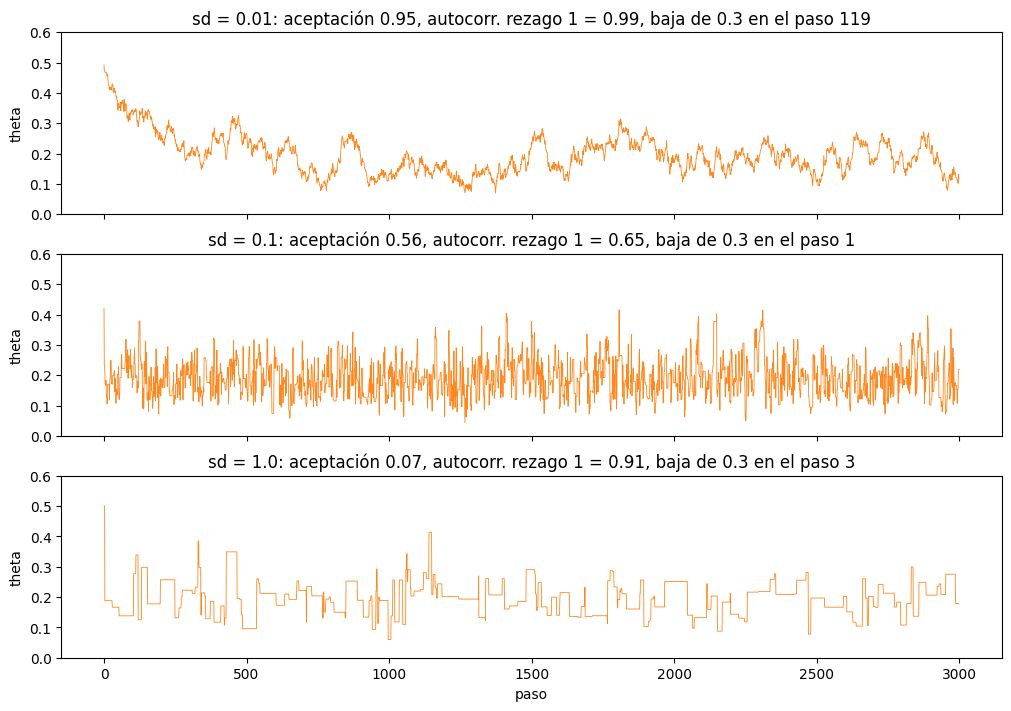

In [9]:
# ¿Qué pasa si cambia el tamaño de la propuesta? sd = 0.01, 0.1 y 1.0
fig, axes = plt.subplots(3, 1, figsize=(10, 7), layout="constrained", sharex=True)
for ax, sd in zip(axes, [0.01, 0.1, 1.0]):
    ch, tasa = metropolis(sd)
    m = ch[2000:]
    ac1 = np.corrcoef(m[:-1], m[1:])[0, 1]                 # autocorrelación de rezago 1
    llega = int(np.argmax(ch < 0.3))                        # primer paso por debajo de 0.3 (zona del posterior)
    ax.plot(ch[:3000], lw=0.6, color="#FF871E")
    ax.set(ylabel="theta", ylim=(0, 0.6), title=f"sd = {sd}: aceptación {tasa:.2f}, autocorr. rezago 1 = {ac1:.2f}, baja de 0.3 en el paso {llega}")
    print(f"sd = {sd:5}: aceptación {tasa:.3f} | autocorrelación {ac1:.3f} | pasos para bajar de 0.3: {llega:4d} | media {m.mean():.3f} | valores distintos: {len(np.unique(ch))}")
axes[-1].set_xlabel("paso")
plt.show()

**Efecto del tamaño de paso (desviación de la propuesta):**

| sd | Aceptación | Traza | Problema |
|---|---|---|---|
| 0.01 | ~95 % | Se mueve como una caminata muy lenta: tarda ~120 pasos en llegar de 0.5 a la zona del posterior y la traza es suave | Casi todo se acepta, pero los pasos son diminutos: autocorrelación de rezago 1 de ~0.99, calentamiento largo y muy pocas muestras efectivas |
| 0.1 | ~56 % | Llega en pocos pasos y oscila alrededor de 0.19 | Equilibrio razonable (autocorrelación ~0.65; en 1 dimensión, una aceptación de 40–55 % suele ser buena) |
| 1.0 | ~7 % | Escalones largos y planos: la cadena se queda "pegada" en el mismo valor | La mayoría de las propuestas cae fuera de (0, 1) o en zonas de poca densidad y se **rechaza** (solo ~1 500 de 20 000 pasos son valores distintos); autocorrelación ~0.91 |

Las tres cadenas dan una media parecida (~0.19), pero la calidad de las muestras (cuántas muestras independientes equivalen) es muy distinta. Un sd bien ajustado equilibra "aceptar mucho" con "moverse lejos": con un paso demasiado chico se acepta casi todo pero se avanza poco, y con uno demasiado grande se propone lejos pero casi todo se rechaza.

---
## Parte 4: El mismo modelo en PyMC

Modelo: $\theta\sim\text{Beta}(a,b)$, $y\sim\text{Binomial}(40,\theta)$, con $y=7$ observado.

In [10]:
def ajustar(a, b):
    with pm.Model():
        theta = pm.Beta("theta", alpha=a, beta=b)
        pm.Binomial("y", n=40, p=theta, observed=7)
        return pm.sample(1000, tune=1000, chains=4, random_seed=2026)

id_plano = ajustar(1, 1)          # prior plano Beta(1, 1)
id_inf = ajustar(2, 18)           # prior informativo Beta(2, 18): media 0.10

NUTS[nutpie]: [theta]


Output()

NUTS[nutpie]: [theta]


Output()

In [11]:
print(az.summary(id_plano))      # media 0.191; 89 %: 0.10 a 0.30
print(az.summary(id_inf))        # media 0.150; 89 %: 0.084 a 0.23

for nombre, idata in [("plano", id_plano), ("informado", id_inf)]:
    th = idata.posterior["theta"].values.ravel()
    print(nombre, (th > 0.25).mean().round(3))
# plano 0.166, informado 0.026

        mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
theta  0.191  0.061      0.1      0.3     1603     1754  1.01    0.0015  0.00087
       mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
theta  0.15  0.045    0.084     0.23     1566     2101  1.00    0.0011  0.00067
plano 0.166
informado 0.026


**2. Diagnósticos.** En ambos modelos $\hat R\approx1.00$–$1.01$ (las 4 cadenas coinciden entre sí; la regla práctica es $\hat R$ cerca de 1, idealmente $<1.01$) y el ESS (tamaño efectivo de muestra) ronda las 1 600–2 100 sobre 4 000 muestras, con un error de Monte Carlo (`mcse_mean` ≈ 0.001–0.0015) mucho menor que la desviación del posterior (0.06 y 0.045). Se puede confiar en la muestra.

**3. Prior del área de riesgo, Beta(2, 18) (media 0.10).** La media posterior pasa de 0.191 a **0.150** y el intervalo de 89 % de (0.10, 0.30) a **(0.084, 0.23)**: el posterior se desplaza hacia el 10 % y se vuelve más estrecho.

**4. Probabilidad de superar 25 % de morosidad** (umbral de rentabilidad):

| Prior | $P(\theta>0.25)$ |
|---|---|
| Plano Beta(1, 1) | **≈ 17 %** |
| Informativo Beta(2, 18) | **≈ 3 %** |

Como el modelo es conjugado, se puede verificar analíticamente: el posterior es Beta(1+7, 1+33) = Beta(8, 34) con prior plano y Beta(2+7, 18+33) = Beta(9, 51) con el informativo.

In [12]:
# Verificación analítica (modelo conjugado Beta-Binomial)
for nombre, (a, b) in {"plano": (1, 1), "informado": (2, 18)}.items():
    post = stats.beta(a + 7, b + 33)
    print(f"{nombre:10s} Beta({a+7},{b+33}): media = {post.mean():.3f}, P(theta > 0.25) = {post.sf(0.25):.3f}")

# Sensibilidad: un prior informativo más débil, Beta(1, 9) (media 0.10 pero vale 10 créditos)
debil = stats.beta(1 + 7, 9 + 33)
print(f"débil Beta(1,9): media = {debil.mean():.3f}, P(theta > 0.25) = {debil.sf(0.25):.3f}")

plano      Beta(8,34): media = 0.190, P(theta > 0.25) = 0.161
informado  Beta(9,51): media = 0.150, P(theta > 0.25) = 0.025
débil Beta(1,9): media = 0.160, P(theta > 0.25) = 0.053


### Para discutir: ¿cuál prior defenderían ante un comité de crédito? ¿Cuántos créditos más harían falta para que el prior dejara de importar?

**Qué prior defender.** Los mismos datos dan dos decisiones distintas (17 % contra 3 % de riesgo de superar el umbral), así que la elección debe justificarse, no escogerse por conveniencia. El prior Beta(2, 18) equivale a haber visto **20 créditos** con 10 % de mora, la mitad del peso de los 40 datos propios. Se puede defender si el área de riesgo **documenta** que existen líneas comparables con esa morosidad; pero la línea es **nueva**, y justamente su comportamiento podría diferir. Una postura prudente ante el comité: (1) presentar **ambos** resultados y el análisis de sensibilidad (un prior más débil, Beta(1, 9), da una probabilidad intermedia); (2) explicar que con 40 créditos la conclusión **depende del prior**, y (3) proponer una decisión que se pueda revisar a medida que lleguen más créditos (límite de colocación inicial más pequeño).

**¿Cuántos créditos más?** El prior pesa como $a+b$ créditos "virtuales": 2 el plano y 20 el informado, frente a $n$ reales. Si la tasa observada se mantiene en 7/40 = 17.5 %, se calcula cuánto se parecen los posteriores al crecer $n$:

In [13]:
tasa_obs = 7 / 40
print(f"{'n':>6s} {'morosos':>8s} {'P(>25%) plano':>14s} {'P(>25%) informado':>18s} {'dif. de medias':>15s}")
for n_ in [40, 100, 200, 400, 800, 1600]:
    k_ = round(tasa_obs * n_)
    p_plano = stats.beta(1 + k_, 1 + n_ - k_)
    p_inf = stats.beta(2 + k_, 18 + n_ - k_)
    print(f"{n_:6d} {k_:8d} {p_plano.sf(0.25):14.3f} {p_inf.sf(0.25):18.3f} {abs(p_plano.mean() - p_inf.mean()):15.4f}")

     n  morosos  P(>25%) plano  P(>25%) informado  dif. de medias
    40        7          0.161              0.025          0.0405
   100       18          0.057              0.012          0.0196
   200       35          0.007              0.002          0.0100
   400       70          0.000              0.000          0.0052
   800      140          0.000              0.000          0.0026
  1600      280          0.000              0.000          0.0013


Con la misma tasa de mora de 17.5 %, la diferencia entre ambos posteriores se achica a medida que crece $n$: con unos **200–400 créditos** ya conducen a la misma conclusión práctica (probabilidad de superar 25 % de ~1 % o menos con ambos priors), porque el peso de los datos ($n$) supera por mucho al del prior ($a+b$ = 2 o 20). Regla práctica: el prior deja de importar cuando $n\gg a+b$ (aquí $n$ de varias centenas frente a 20). Es la idea de **actualizar una creencia con datos**, que vuelve en bandidos multibrazo (semana 14).

---
## Parte 5: Reflexión

**Observación matemática.** Lo más sorprendente de la obra es que el plan "más probable" (100 días) se cumple solo el 15 % de las veces: la media es ~112 días y hay un 22.5 % de pasarse del contrato, por la asimetría de las colas y porque los retrasos se acumulan; y que acortar un solo peor caso (permisos) baja el riesgo de 22.5 % a 3.6 %. De la morosidad sorprende que 40 créditos son pocos: el intervalo de 89 % va de 10 % a 30 %, y la decisión sobre el umbral de 25 % cambia por completo (17 % contra 3 %) solo con el prior.

**Observación técnica.** PyMC hizo por nosotros lo que en la parte 3 tuvimos que programar a mano: (1) escribir el posterior a partir del modelo (prior + verosimilitud) sin derivar $\log g(\theta)$; (2) **elegir el algoritmo y ajustar el tamaño de paso automáticamente** (NUTS usa gradientes y adapta el paso durante `tune`, sin probar sd = 0.01, 0.1, 1.0 a mano); (3) el **calentamiento** (descarta `tune` pasos); (4) correr varias **cadenas** en paralelo; y (5) los **diagnósticos** ($\hat R$, ESS, `mcse`) en `az.summary`.

**Pregunta abierta.** ¿Qué cantidad incierta de nuestro proyecto vale la pena simular, y qué prior le pondríamos? _(completar según el carril del grupo: p. ej. la tasa de transmisión $\beta$ en un modelo epidemiológico con prior $\text{LogNormal}$ centrado en valores de la literatura; el tiempo de entrega de un proceso con triangular (mín., más probable, máx.); la tasa de conversión con un prior Beta basado en campañas previas.)_